In [15]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

df=pd.read_csv('../data/train.csv')
df_1=df.copy()

In [16]:
print(df.head())

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN        S  


In [17]:
print(df['Embarked'].unique())

<StringArray>
['S', 'C', 'Q', nan]
Length: 4, dtype: str


In [18]:
print(df['Embarked'].unique().value_counts)

<bound method StringArray.value_counts of <StringArray>
['S', 'C', 'Q', nan]
Length: 4, dtype: str>


In [19]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [20]:
print(df['Age'].max())
print(df['Age'].mean())
print(df['Age'].min())
#see some information from age

80.0
29.69911764705882
0.42


In [21]:
df['Age']=df['Age'].fillna(df['Age'].mean())
print(df.isnull().sum())
#fill age mean

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [22]:
#cost of ticket
print(f'ticket max cost {df['Fare'].max()}, ticket mean cost {df['Fare'].mean()}, ticket min cost {df['Fare'].min()}')

ticket max cost 512.3292, ticket mean cost 32.204207968574636, ticket min cost 0.0


Text(0.5, 1.0, 'Survived')

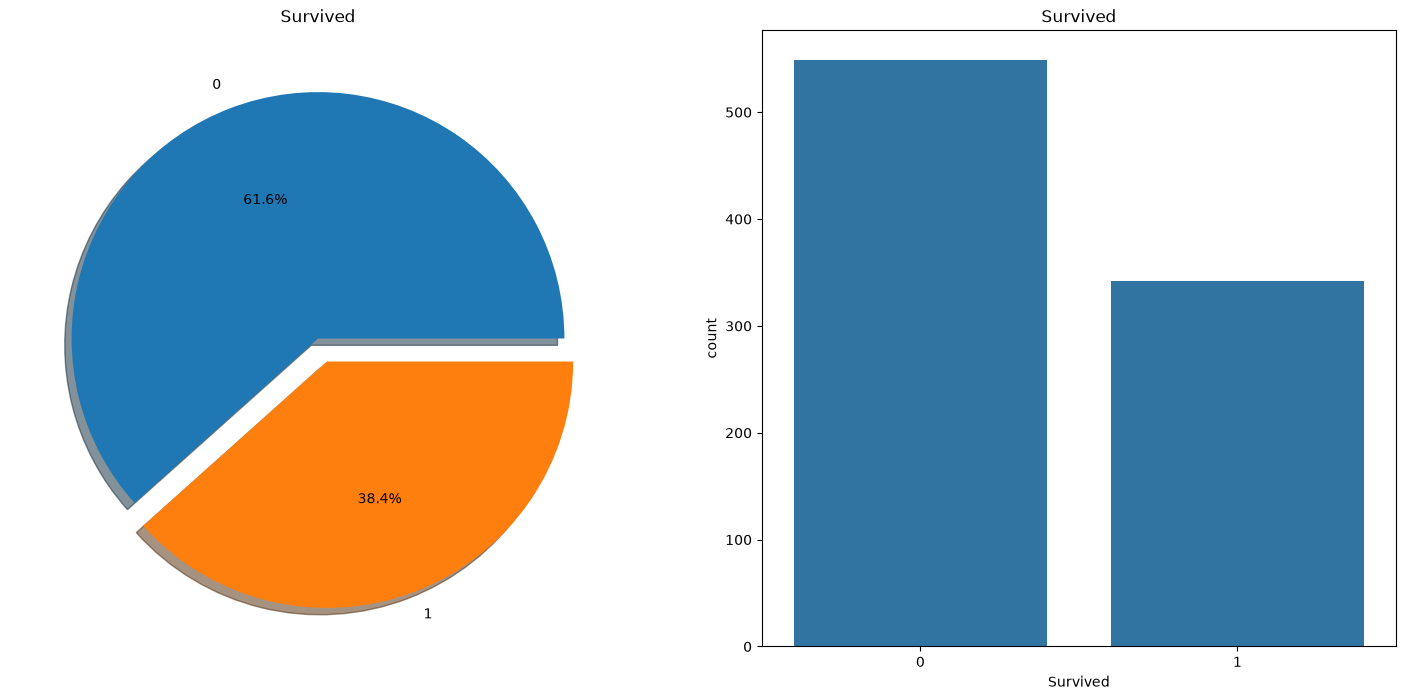

In [24]:
#see how many peoples survived
f,ax=plt.subplots(1,2,figsize=(18,8))
df['Survived'].value_counts().plot.pie(explode=[0,0.1],autopct='%1.1f%%',ax=ax[0],shadow=True)
ax[0].set_title('Survived')
ax[0].set_ylabel('')
sns.countplot(x='Survived',data=df,ax=ax[1])
ax[1].set_title('Survived')

Text(0.5, 1.0, 'Sex:Survived vs Dead')

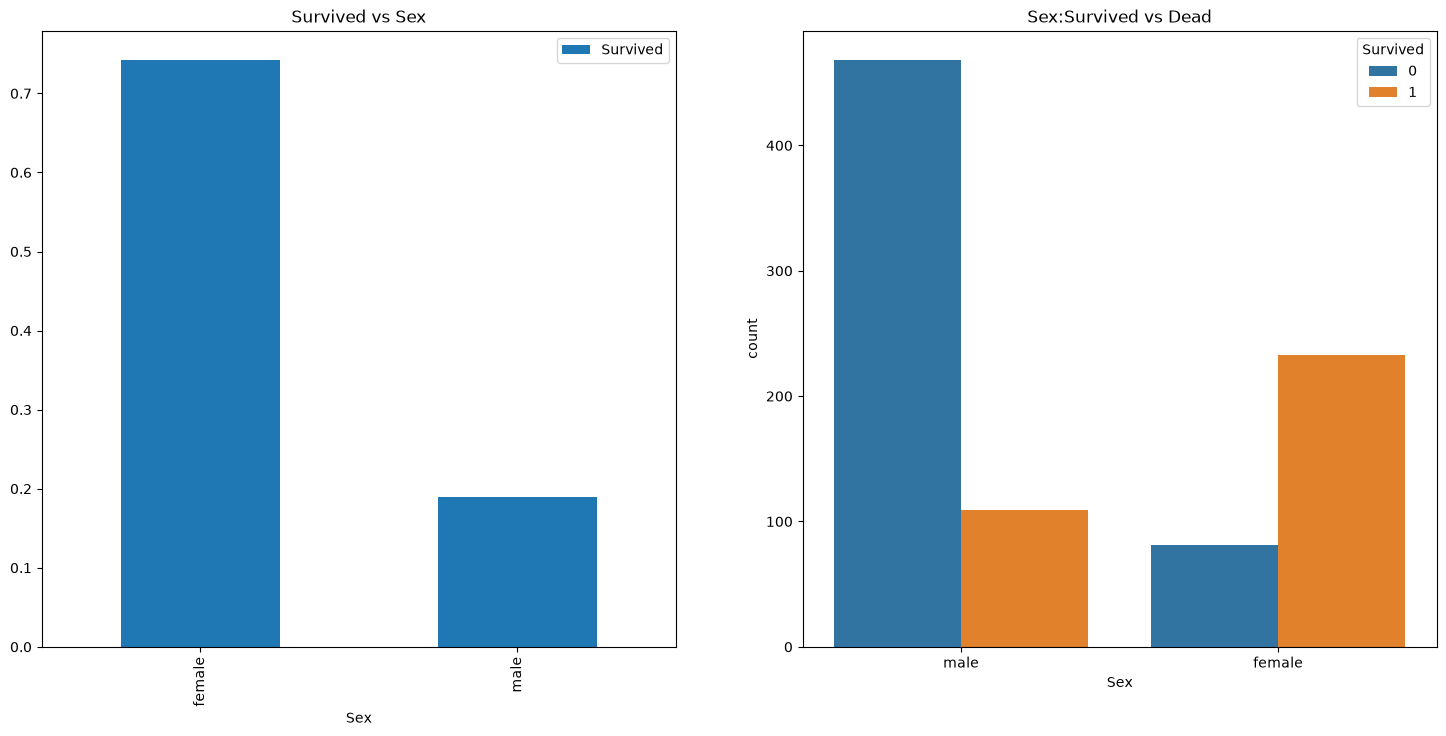

In [26]:
# in graphs see only 38% people survive
#lets see who survived more
f,ax=plt.subplots(1,2,figsize=(18,8))
df[['Sex','Survived']].groupby(['Sex']).mean().plot.bar(ax=ax[0])
ax[0].set_title('Survived vs Sex')
sns.countplot(x='Sex',hue='Survived',data=df,ax=ax[1])
ax[1].set_title('Sex:Survived vs Dead')

[3 1 2]


Text(0.5, 1.0, 'Pclass:Survived vs Dead')

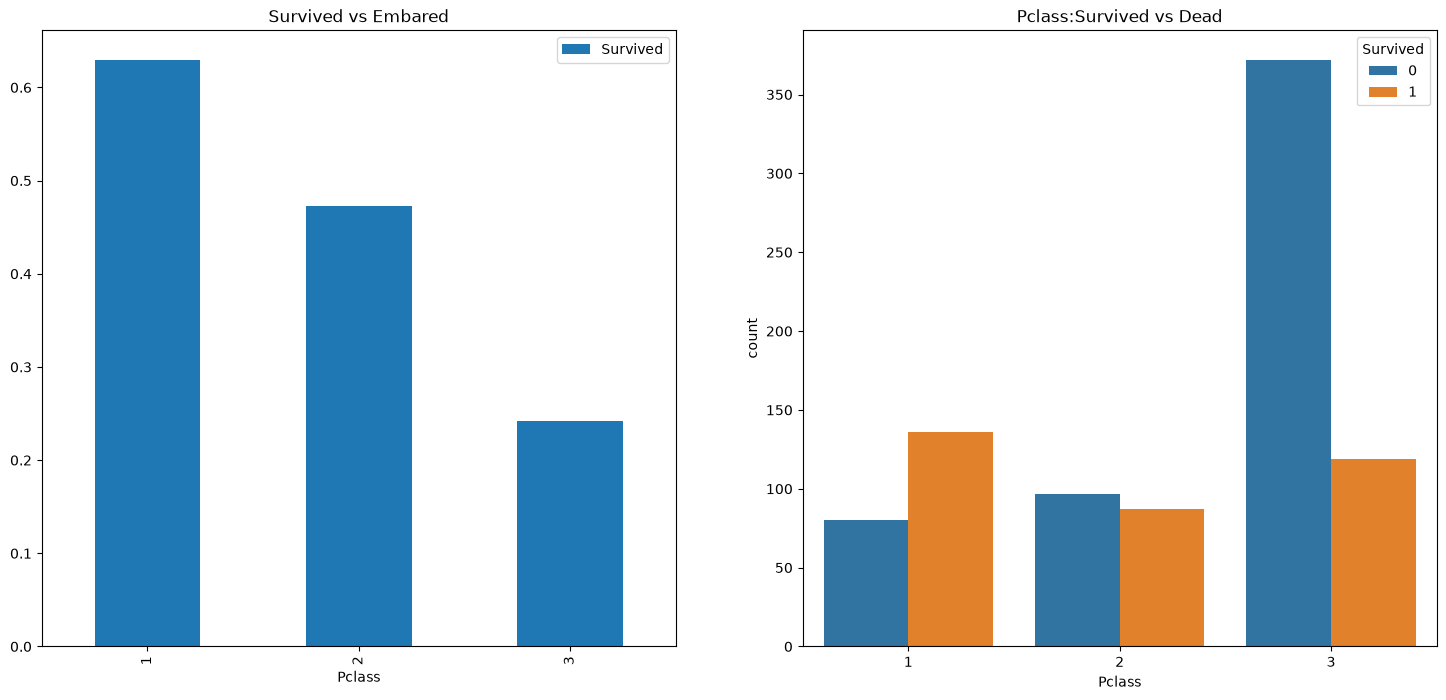

In [28]:
#woman survived in 0.75, man in last. In all count of womans and mans, mans survived 100 in 500 mans and womans 250 in 350 thats huge gap
#how class of ticket affects to survive
print(df['Pclass'].unique()) #unique classes of tickets
f,ax=plt.subplots(1,2,figsize=(18,8))
df[['Pclass','Survived']].groupby(['Pclass']).mean().plot.bar(ax=ax[0])
ax[0].set_title('Survived vs Embared')
sns.countplot(x='Pclass',hue='Survived',data=df,ax=ax[1])
ax[1].set_title('Pclass:Survived vs Dead')

Text(0.5, 1.0, 'Age:Survived vs Dead')

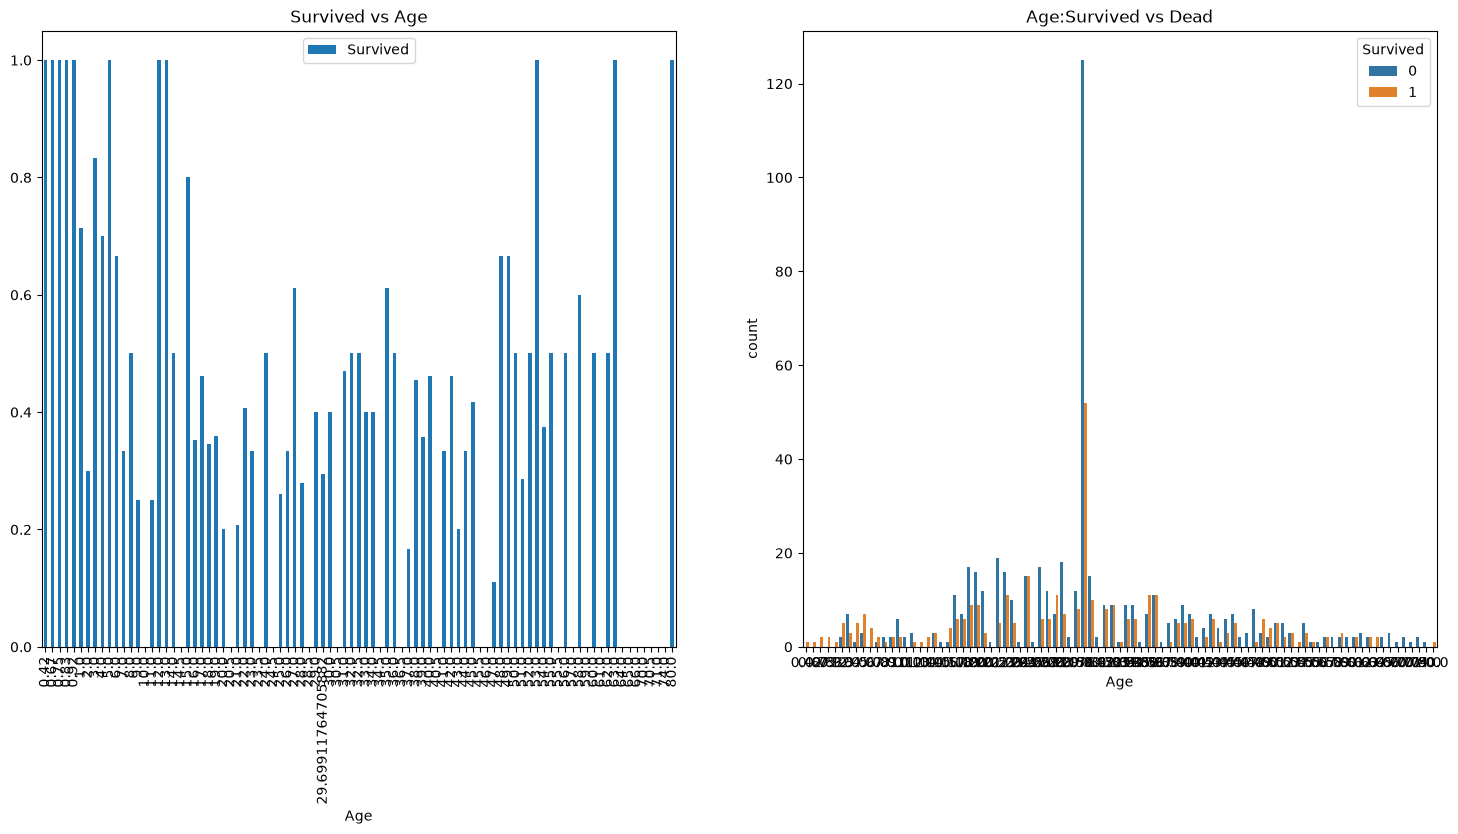

In [31]:
#s - low priority (220/650) c - medium (100/180) q - premium (25/70)
#most of peoples saves as medium class of tickets

#lets see how age affects to survive
f,ax=plt.subplots(1,2,figsize=(18,8))
df[['Age','Survived']].groupby(['Age']).mean().plot.bar(ax=ax[0])
ax[0].set_title('Survived vs Age')
sns.countplot(x='Age',hue='Survived',data=df,ax=ax[1])
ax[1].set_title('Age:Survived vs Dead')
#people < 14 years more survive

Text(0.5, 1.0, 'Age:Survived vs Dead')

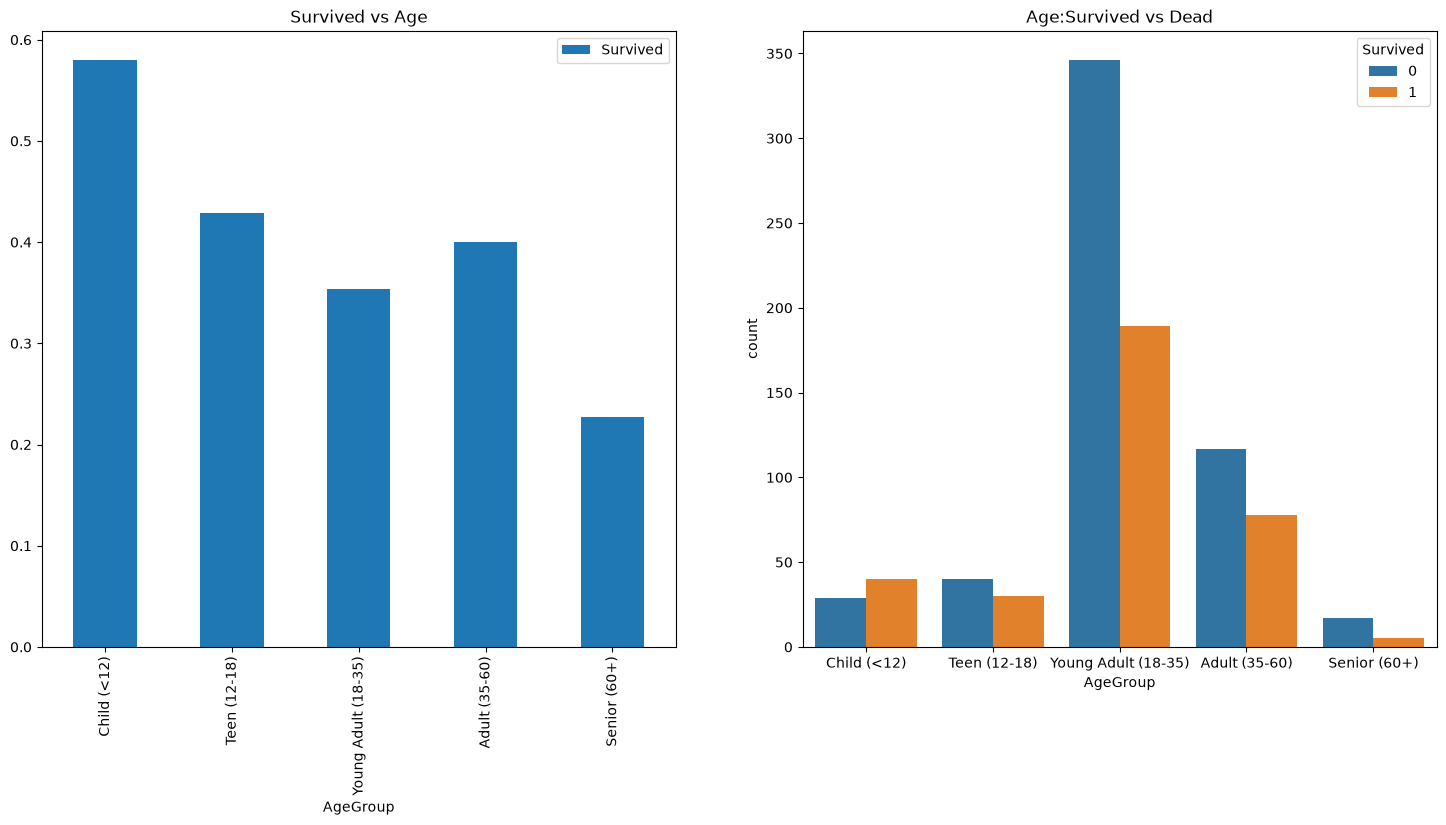

In [ ]:
bins = [0, 12, 18, 35, 60, 100]
labels = ['Child (<12)', 'Teen (12-18)', 'Young Adult (18-35)', 'Adult (35-60)', 'Senior (60+)']
df['AgeGroup'] = pd.cut(df['Age'], bins=bins, labels=labels, right=True)

f,ax=plt.subplots(1,2,figsize=(18,8))
df[['AgeGroup','Survived']].groupby(['AgeGroup']).mean().plot.bar(ax=ax[0])
ax[0].set_title('Survived vs Age')
sns.countplot(x='AgeGroup',hue='Survived',data=df,ax=ax[1])
ax[1].set_title('Age:Survived vs Dead')
#people 18-35 years more survive